In [1]:
from sklearn.datasets import load_diabetes
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the Diabetes dataset
diabetes = load_diabetes(as_frame=True)

# Convert dataset into DataFrame
df = diabetes.frame

# Display first 5 records
print("Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Dataset Shape: (442, 11)


In [2]:
# Select the 10 input features
X = df.drop("target", axis=1)

print("Features used for clustering:")
print(X.columns)

Features used for clustering:
Index(['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6'], dtype='object')


In [3]:
# Standardize the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

Standardized data shape: (442, 10)


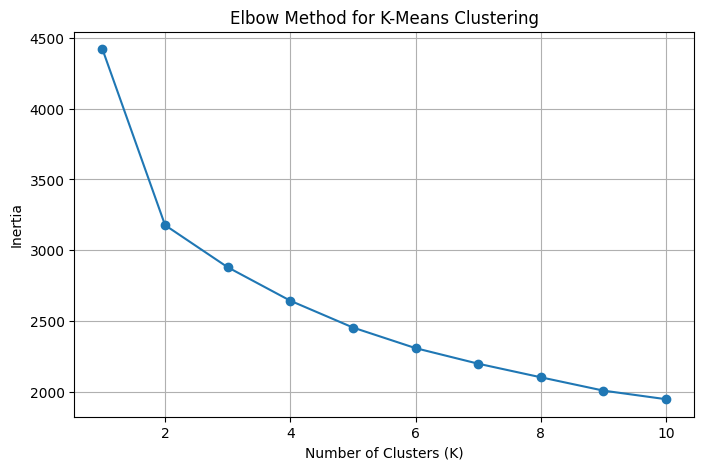

In [4]:
# Elbow Method

inertia = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)
    inertia.append(model.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")

plt.grid(True)
plt.show()

In [5]:
# Create K-Means model
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Fit model and predict clusters
labels = kmeans.fit_predict(X_scaled)

# Display cluster labels
print("Cluster Labels:")
print(labels)

# Display cluster centers
print("\nCluster Centers:")
print(kmeans.cluster_centers_)

Cluster Labels:
[1 2 1 1 2 2 2 0 1 1 2 1 2 1 2 0 1 0 2 2 2 2 2 0 2 1 2 1 2 1 2 2 1 2 2 2 1
 2 0 1 0 2 1 2 1 1 2 2 1 1 1 1 2 1 2 2 1 2 2 0 2 1 2 2 1 0 1 1 1 2 2 0 0 0
 1 1 1 2 2 2 0 1 2 2 2 1 2 2 2 2 2 0 1 2 2 2 1 0 1 1 0 1 2 0 2 1 2 1 1 0 2
 2 2 0 0 0 0 0 0 2 2 0 0 0 2 1 2 2 2 0 1 2 1 2 2 1 2 1 1 1 1 0 0 2 0 1 0 0
 1 1 1 2 0 1 1 0 2 0 2 1 2 0 2 1 2 2 2 0 0 0 2 2 0 2 1 2 1 0 2 0 1 2 0 1 1
 1 0 2 0 2 1 1 1 0 2 0 2 1 2 1 2 2 0 0 1 1 0 1 0 1 2 1 1 2 2 1 0 0 2 2 2 2
 1 2 2 1 2 1 2 2 0 1 0 2 1 1 0 2 1 0 1 1 2 1 1 2 2 2 0 0 1 0 0 0 0 2 1 2 0
 1 2 2 0 2 1 1 2 0 0 2 1 1 2 0 1 1 0 2 1 1 1 2 0 2 1 0 2 0 1 0 0 0 2 1 1 1
 2 2 1 1 1 1 0 0 0 1 1 0 2 0 1 0 2 0 1 2 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 0
 1 2 2 0 1 2 0 1 1 1 1 0 0 0 1 2 1 0 2 2 0 0 1 2 1 2 0 1 2 1 1 1 1 0 0 0 1
 2 0 1 2 2 0 0 0 1 2 1 2 1 1 0 1 2 2 1 2 0 2 1 2 0 2 2 1 1 1 1 2 0 1 1 1 2
 1 0 0 0 2 0 2 0 0 1 2 0 2 1 0 0 0 1 2 0 1 0 2 2 1 0 2 2 2 2 1 0 1 1 2]

Cluster Centers:
[[ 0.38199387  0.26387842  0.53445356  0.46928495  1.08200579  1.0353

In [6]:
# Count number of samples in each cluster
cluster_counts = pd.Series(labels).value_counts().sort_index()

print("Number of samples in each cluster:")
print(cluster_counts)

Number of samples in each cluster:
0    125
1    159
2    158
Name: count, dtype: int64


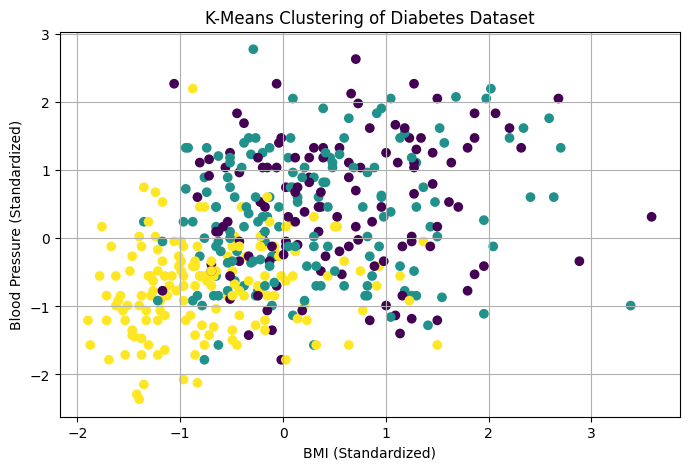

In [7]:
# Get column positions
bmi_index = X.columns.get_loc("bmi")
bp_index = X.columns.get_loc("bp")

# Plot clusters using BMI and BP
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, bmi_index],
    X_scaled[:, bp_index],
    c=labels
)

plt.xlabel("BMI (Standardized)")
plt.ylabel("Blood Pressure (Standardized)")
plt.title("K-Means Clustering of Diabetes Dataset")

plt.grid(True)
plt.show()

In [8]:
print("K-Means Clustering Completed Successfully")
print("Number of Clusters:", 3)
print("Number of Data Points:", len(X))

K-Means Clustering Completed Successfully
Number of Clusters: 3
Number of Data Points: 442
